In [2]:
# Autoreload all modules so that changes in the code are reflected without needing to restart the kernel
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Event-Aligned LFP Power: Single-Trial Baseline Z-Scores

This pipeline follows `time_based_analysis.ipynb`, adding reusable baseline-normalized
**spectrograms and mean +/- SEM time traces**. Each individual nose poke has its own
baseline from **-3 to -1 seconds**. Baseline mean and sample SD are estimated separately
for every trial, frequency, and region, before averaging trials.

Power is recalculated from saved `rms_traces` with the recording's multitaper settings.
Time labels are **spectral window centers**, unlike the start-labeled stored spectra in
the older notebook. No raw Trodes preprocessing is repeated. This notebook analyzes
power only; coherence and Granger remain in the original notebook.

One trialwise CSV per recording exports the normalized values used by both plot types,
with frequencies across columns. Detailed baseline/QC tables remain in memory. A z-score is a descriptive normalization, not a
significance test. Three overlapping baseline estimates give a potentially noisy SD.


## Imports


In [3]:
from datetime import datetime, timezone
from pathlib import Path
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "coop_ephys_analysis").is_dir()), None,
)
if REPO_ROOT is None:
    raise FileNotFoundError("Start Jupyter inside coop_ephys_analysis or set REPO_ROOT.")
# The behavior module also imports the repository's top-level external package.
for path in (REPO_ROOT, REPO_ROOT / "src"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from coop_ephys_analysis.behavior import load_pickle
from coop_ephys_analysis.lfp import (
    build_condition_dict,
    calculate_event_baseline_power,
    export_event_baseline_trialwise_csv,
    load_event_baseline_collection,
    plot_baselined_event_average_spectrogram,
    plot_baselined_event_average_traces,
    update_collection_events_from_behavior,
)


## Select the Day and Inputs

The RMS-only loader uses the same saved collection directory as the existing notebook.
It returns a collection compatible with the new functions and event-import helpers.
The functions also accept an existing full `LFPCollection` loaded elsewhere.


In [4]:
DAY = 1
LFP_DATA_ROOT = Path(r"D:\PadillaCoreanoLab\Coop_Ephys")
collection_path = LFP_DATA_ROOT / f"D{DAY}_lfp_collection" / "lfp_collection.json"
behavior_path = REPO_ROOT / "data" / "processed" / "stage4_thresholded" / f"Stage4_D{DAY}.pkl"
for path in (collection_path, behavior_path):
    if not path.is_file():
        raise FileNotFoundError(path)

collection = load_event_baseline_collection(collection_path)
print(f"Loaded Day {DAY}: {len(collection.recordings)} recordings (RMS traces and metadata)")
display(pd.DataFrame([
    {"recording": rec.name, "window_s": rec.timewindow, "step_s": rec.timestep,
     "sampling_rate_hz": rec.resample_rate, "excluded_regions": rec.excluded_regions}
    for rec in collection.recordings
]))


Loaded Day 1: 10 recordings (RMS traces and metadata)


,recording,window_s,step_s,sampling_rate_hz,excluded_regions
0,20250508_100203_Stage4_D1_1-2_merged.rec,1.0,0.5,1000.0,[]
1,20250508_100203_Stage4_D1_1-3_merged.rec,1.0,0.5,1000.0,[]
2,20250508_100203_Stage4_D1_2-1_merged.rec,1.0,0.5,1000.0,[]
3,20250508_100203_Stage4_D1_2-4_merged.rec,1.0,0.5,1000.0,[]
4,20250508_112121_Stage4_D1_6-1_merged.rec,1.0,0.5,1000.0,[]
5,20250508_112121_Stage4_D1_6-3_merged.rec,1.0,0.5,1000.0,[]
6,20250509_131426_Stage4_D1_4-1_merged.rec,1.0,0.5,1000.0,[]
7,20250509_131426_Stage4_D1_4-2_merged.rec,1.0,0.5,1000.0,[]
8,20250509_131426_Stage4_D1_4-3_merged.rec,1.0,0.5,1000.0,[]
9,20250509_131426_Stage4_D1_4-4_merged.rec,1.0,0.5,1000.0,[]


## Import Saved Events and Conditions

Use the saved filtered nose pokes, including forced-trial removal if saved during
behavior QC. This notebook does not rerun matching or remove another batch.
The import converts behavior seconds to milliseconds. Global ITI events are imported
but are **not** used as the normalization reference.


In [5]:
processed_behaviors = load_pickle(behavior_path)
event_update_summary = update_collection_events_from_behavior(
    collection, processed_behaviors, source_unit="seconds", strict=True,
)
condition_dict = build_condition_dict(collection)
SELFISH_EVENT = "filtered selfish nose poke"
COOP_EVENT = "filtered coop nose poke"
display(pd.DataFrame([
    {"recording": rec.name, "condition": rec.condition,
     SELFISH_EVENT: len(rec.event_dict.get(SELFISH_EVENT, [])),
     COOP_EVENT: len(rec.event_dict.get(COOP_EVENT, []))}
    for rec in collection.recordings
]))
print("Unused behavior recordings:", event_update_summary["unused_behavior_recordings"])


,recording,condition,filtered selfish nose poke,filtered coop nose poke
0,20250508_100203_Stage4_D1_1-2_merged.rec,subject with recipient,33,105
1,20250508_100203_Stage4_D1_1-3_merged.rec,recipient,33,105
2,20250508_100203_Stage4_D1_2-1_merged.rec,recipient,46,62
3,20250508_100203_Stage4_D1_2-4_merged.rec,subject with recipient,46,62
4,20250508_112121_Stage4_D1_6-1_merged.rec,subject alone,24,127
5,20250508_112121_Stage4_D1_6-3_merged.rec,subject alone,41,61
6,20250509_131426_Stage4_D1_4-1_merged.rec,recipient,106,96
7,20250509_131426_Stage4_D1_4-2_merged.rec,recipient,26,156
8,20250509_131426_Stage4_D1_4-3_merged.rec,subject with recipient,106,96
9,20250509_131426_Stage4_D1_4-4_merged.rec,subject with recipient,26,156


Unused behavior recordings: []


## Shared Calculation and Export Settings

Each 1-second power window must fit entirely inside the baseline. With -3 to -1 s
and a 0.5-second step, its window centers are -2.5, -2.0, and -1.5 s. All three
must be finite, and their sample SD must be positive. Invalid values stay missing.
Overlap with other annotated behavior is flagged but not automatically excluded.

The requested display centers run from -3.5 to +3.5 s (upper endpoint excluded).
An additional half-window of signal is required on both sides. Missing recording-edge
support excludes that occurrence; per-region artifacts can invalidate only that region.
`event_len=None` instead uses actual event durations.

`FREQ_RANGE` is inclusive and controls which frequencies are kept/exported. Set it to
`None` to retain all computed frequencies (much larger CSVs). `COLOR_LIMIT` only clips
the displayed color range; numerical values are never clipped. `SPECTROGRAM_CMAP`
sets the palette: `PuOr` shows decreases in orange, zero near white, and increases
in purple. Use the same palette and color limit across conditions. Band traces average
frequency-specific z-scores after trial averaging within each recording.


In [6]:
FREQ_RANGE = (0, 100)
PRE_WINDOW = 3.5
EVENT_LEN = 3
POST_WINDOW = 0
REGIONS = None
# Subject -> recipient; export fills the reverse pairing automatically.
PAIRING_DICT = {
    "1-2": "1-3",
    "2-4": "2-1",
    "4-4": "4-2",
    "4-3": "4-1",
}
BASELINE_WINDOW = (-3.0, -1.0)
BASELINE_DDOF = 1
MIN_BASELINE_ESTIMATES = 3
COLOR_LIMIT = 4.0
SPECTROGRAM_CMAP = "PuOr"
EXPORT_CSV = True
SAVE_FIGURES = False
OVERWRITE_EXPORTS = False

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUTPUT_DIR = REPO_ROOT / "results" / "lfp" / "event_baseline" / f"D{DAY}" / RUN_ID

common = dict(
    mode="power", condition_recordings=condition_dict,
    event_len=EVENT_LEN, pre_window=PRE_WINDOW, post_window=POST_WINDOW,
    freq_range=FREQ_RANGE, regions=REGIONS, baseline_window=BASELINE_WINDOW,
    baseline_ddof=BASELINE_DDOF, min_baseline_estimates=MIN_BASELINE_ESTIMATES,
)
print("Output directory:", OUTPUT_DIR)


Output directory: c:\Users\zhaoz\Desktop\Research\Cooperation\coop_ephys_analysis\results\lfp\event_baseline\D1\20261106T200503_275170Z


## Calculate Each Selection Once

These are the same power comparisons as `time_based_analysis.ipynb`: selfish versus
cooperative for subjects with a recipient, and selfish events alone versus with a
recipient. Edit or add entries to reuse the functions for other events/conditions.

Results retain trial tables; both plot types below reuse these objects without another
spectral calculation. Recordings receive equal weight, regardless of event count.
If combining multiple days later, this is not automatically equal weighting by animal.


In [8]:
selections = {
    "selfish_social": (SELFISH_EVENT, "subject with recipient"),
    "coop_social": (COOP_EVENT, "subject with recipient"),
}
baseline_results = {}
for key, (event, condition) in selections.items():
    print("Calculating", key, flush=True)
    result = calculate_event_baseline_power(
        collection, event=event, selected_condition=condition, **common,
    )
    result["settings"]["inputs"] = {
        "collection_json": str(collection_path.resolve()),
        "behavior_pickle": str(behavior_path.resolve()), "day": DAY,
    }
    baseline_results[key] = result
    print("Events with any valid normalized data:", result["event_counts"])
    if result["skipped_recordings"]:
        print("Skipped recordings:", result["skipped_recordings"])


Calculating selfish_social
Events with any valid normalized data: {'20250508_100203_Stage4_D1_1-2_merged.rec': 33, '20250508_100203_Stage4_D1_2-4_merged.rec': 46, '20250509_131426_Stage4_D1_4-3_merged.rec': 106, '20250509_131426_Stage4_D1_4-4_merged.rec': 26}
Calculating coop_social
Events with any valid normalized data: {'20250508_100203_Stage4_D1_1-2_merged.rec': 105, '20250508_100203_Stage4_D1_2-4_merged.rec': 62, '20250509_131426_Stage4_D1_4-3_merged.rec': 96, '20250509_131426_Stage4_D1_4-4_merged.rec': 156}


## Inspect Baseline Quality Before Interpreting Plots

Counts of usable values can differ by region/frequency and time. `event_counts` counts
occurrences with at least one usable normalized point; it is not a per-region trial count.
Use the following tables for detailed counts. A very small positive SD can produce a
large z-score; this pipeline does not hide or threshold those values.


In [9]:
qc_summary = []
for key, result in baseline_results.items():
    stats = result["tables"]["baseline_statistics"]
    summary = stats.groupby(["recording", "region", "status"], dropna=False).size().reset_index(name="trial_frequency_count")
    summary.insert(0, "selection", key)
    qc_summary.append(summary)
display(pd.concat(qc_summary, ignore_index=True))

example = baseline_results["selfish_social"]
display(example["tables"]["baseline_statistics"].head(12))
display(example["tables"]["event_qc"].head())


,selection,recording,region,status,trial_frequency_count
0,selfish_social,20250508_100203_Stage4_D1_1-2_merged.rec,BLA,missing_baseline_power,404
1,selfish_social,20250508_100203_Stage4_D1_1-2_merged.rec,BLA,ok,2929
2,selfish_social,20250508_100203_Stage4_D1_1-2_merged.rec,IC,missing_baseline_power,404
3,selfish_social,20250508_100203_Stage4_D1_1-2_merged.rec,IC,ok,2929
4,selfish_social,20250508_100203_Stage4_D1_1-2_merged.rec,LH,ok,3333
...,...,...,...,...,...
63,coop_social,20250509_131426_Stage4_D1_4-4_merged.rec,MD,ok,15756
64,coop_social,20250509_131426_Stage4_D1_4-4_merged.rec,NAc,missing_baseline_power,101
65,coop_social,20250509_131426_Stage4_D1_4-4_merged.rec,NAc,ok,15655
66,coop_social,20250509_131426_Stage4_D1_4-4_merged.rec,mPFC,missing_baseline_power,101


,recording,subject,condition,event,trial_id,event_index,event_onset_s,region,frequency_hz,baseline_mean,baseline_sd,n_baseline_estimates,n_expected_estimates,status,overlapping_events
0,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",0,485.7793,mPFC,0.0,0.000165,0.000100,3,3,ok,"[""recipient port entry""]"
1,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",0,485.7793,IC,0.0,0.026833,0.009047,3,3,ok,"[""recipient port entry""]"
2,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",0,485.7793,NAc,0.0,0.083619,0.035689,3,3,ok,"[""recipient port entry""]"
3,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",0,485.7793,MD,0.0,0.012408,0.015292,3,3,ok,"[""recipient port entry""]"
4,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",0,485.7793,LH,0.0,0.002118,0.000934,3,3,ok,"[""recipient port entry""]"
5,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",0,485.7793,BLA,0.0,0.044884,0.021458,3,3,ok,"[""recipient port entry""]"
6,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",0,485.7793,mPFC,1.0,0.000297,0.000244,3,3,ok,"[""recipient port entry""]"
7,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",0,485.7793,IC,1.0,0.013626,0.005103,3,3,ok,"[""recipient port entry""]"
8,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",0,485.7793,NAc,1.0,0.042303,0.017711,3,3,ok,"[""recipient port entry""]"
9,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",0,485.7793,MD,1.0,0.014284,0.014773,3,3,ok,"[""recipient port entry""]"


,recording,subject,condition,event,trial_id,event_index,event_onset_s,event_stop_s,onset_rounding_error_s,baseline_start_s,baseline_stop_s,overlapping_events,n_valid_region_frequencies,n_total_region_frequencies,status
0,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",0,485.77930,486.00935,-0.00030,482.779,484.779,"[""recipient port entry""]",606,606,ok
1,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",1,494.62945,494.81945,-0.00045,491.629,493.629,"[""recipient port entry"", ""subject port entry""]",303,606,partial
2,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",2,500.88950,501.03950,0.00050,497.890,499.890,"[""recipient port entry"", ""selfish light"", ""sub...",505,606,partial
3,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",3,507.40985,507.55960,0.00015,504.410,506.410,"[""selfish light"", ""subject port entry""]",505,606,partial
4,20250508_100203_Stage4_D1_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250508_100203_Stage4_D1_1-2_merged.rec"", ""...",4,516.33970,516.49995,0.00030,513.340,515.340,"[""subject port entry""]",606,606,ok


## Baseline-Normalized Spectrograms

All selections and regions use the same symmetric color limits. Zero denotes baseline
mean power in SD units. Dashed/dotted markers indicate event onset and baseline bounds.


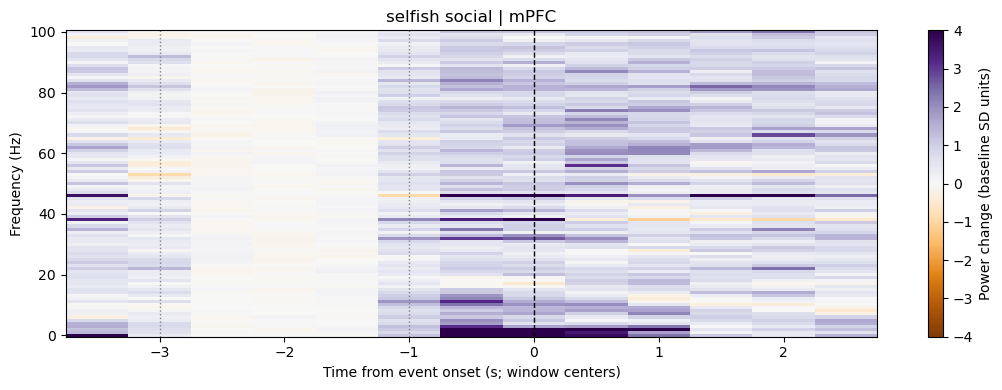

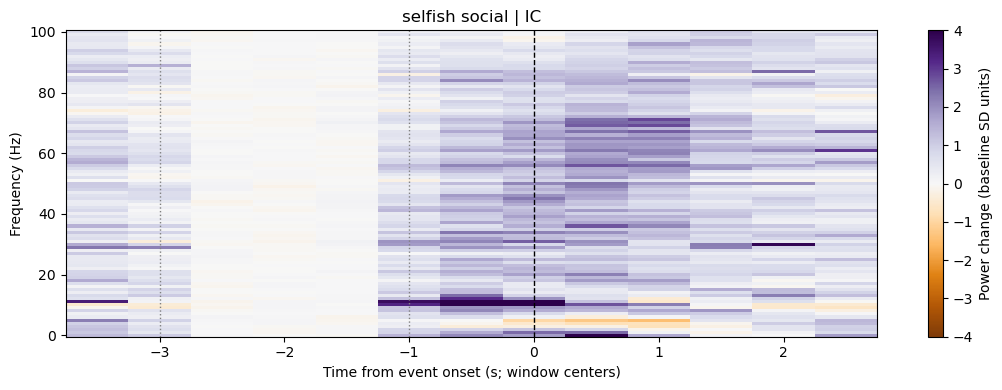

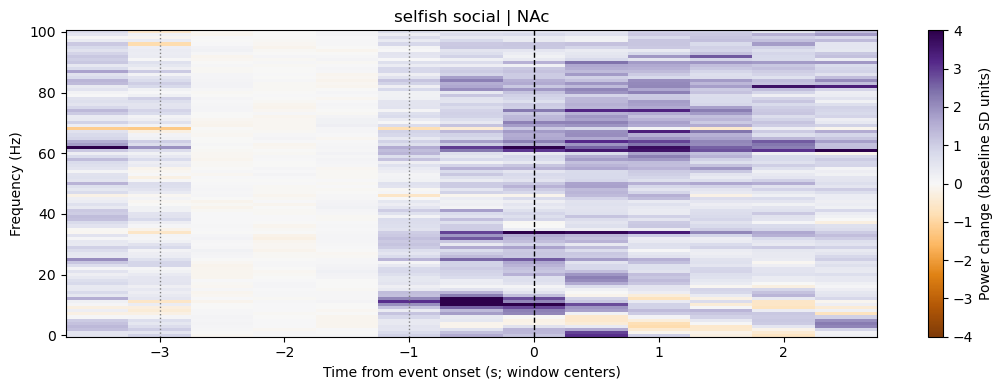

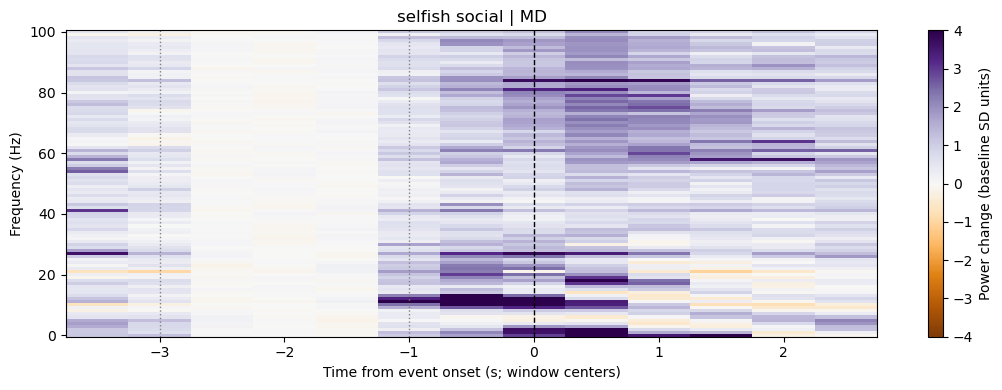

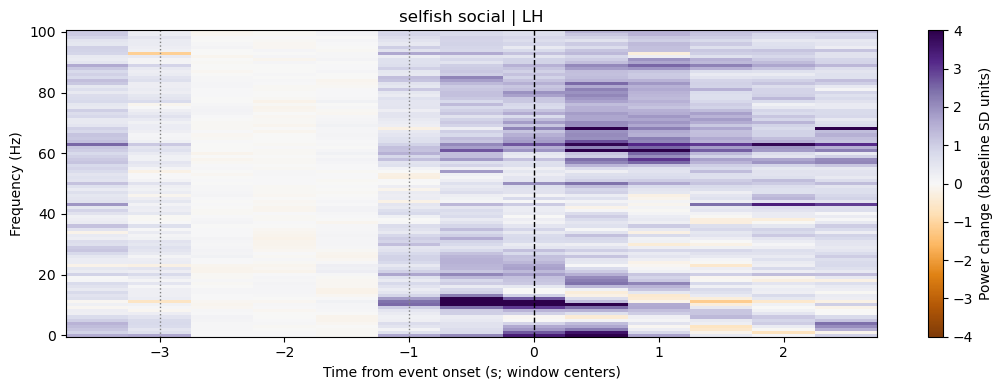

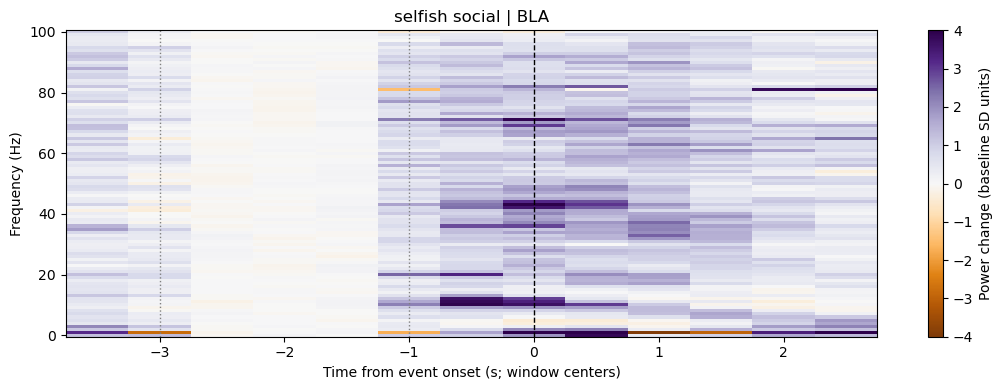

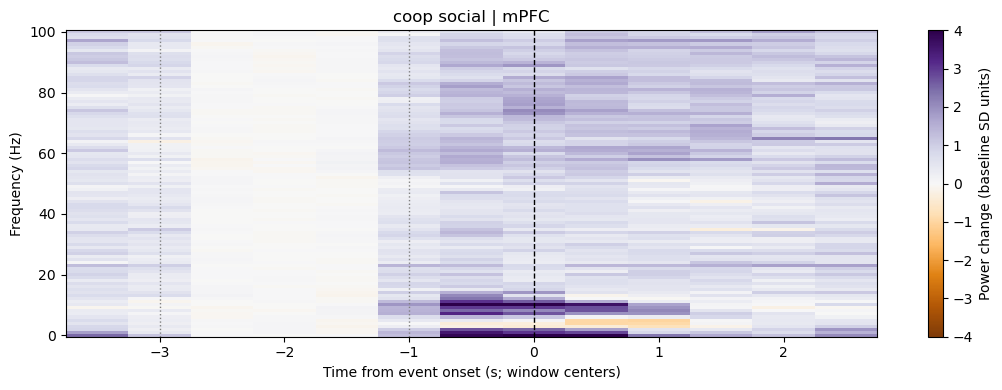

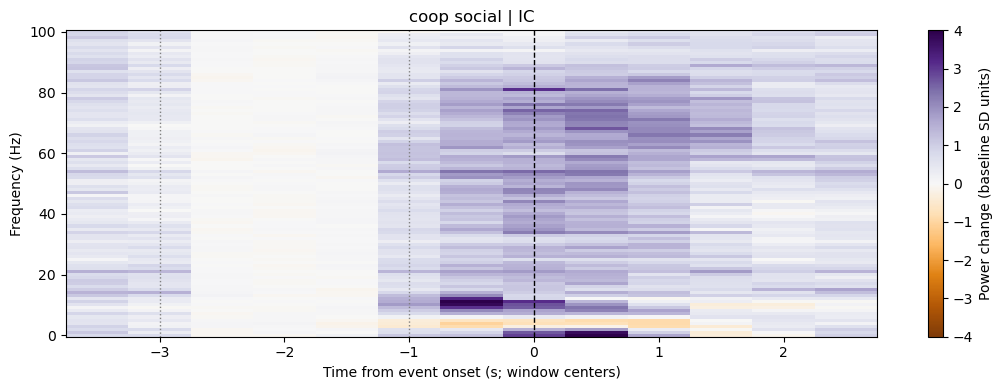

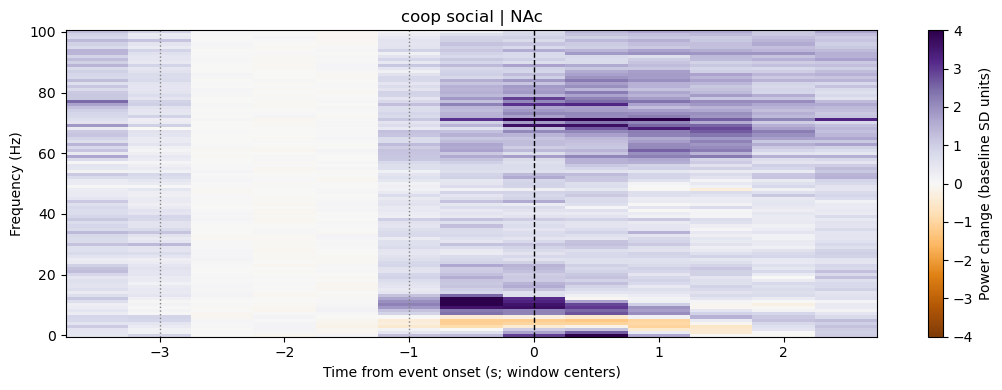

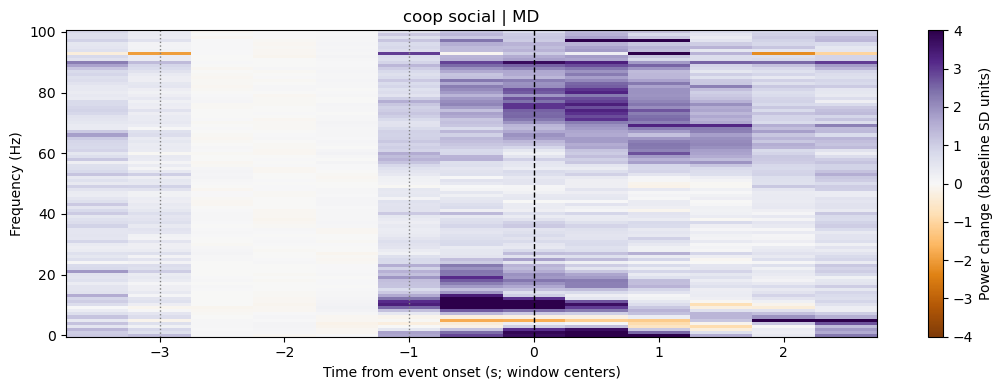

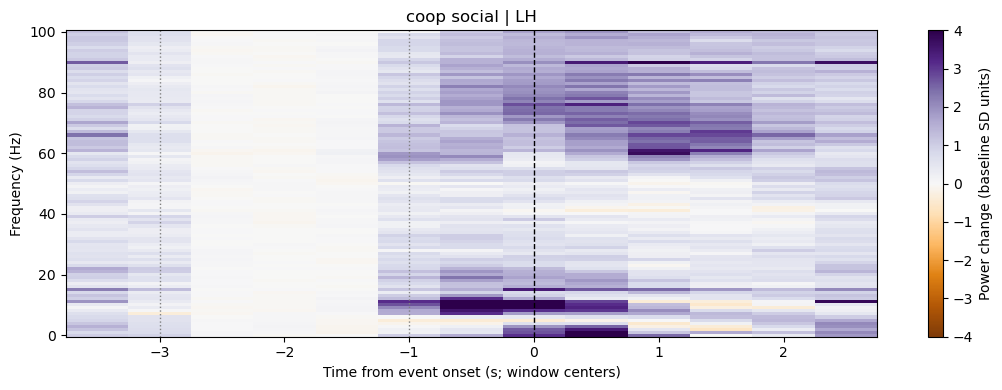

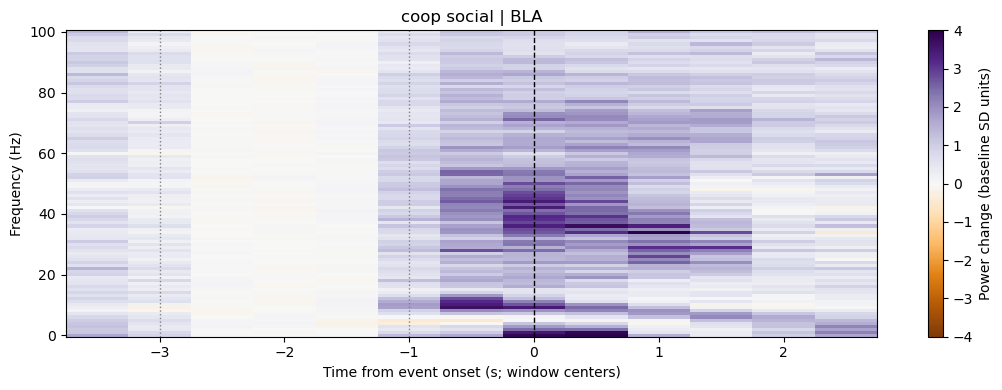

In [10]:
spectrogram_results = {}
for key, result in baseline_results.items():
    spectrogram_results[key] = plot_baselined_event_average_spectrogram(
        result, color_limit=COLOR_LIMIT, cmap=SPECTROGRAM_CMAP, title=key.replace("_", " "),
    )
    plt.show()


## Time Traces: Selfish versus Cooperative

Shading is SEM across recording means, not pooled trials. SEM is undefined when fewer
than two recordings contribute. The line plots and heatmaps use the same normalized
trial data. These plots do not perform significance tests or paired-difference analysis.


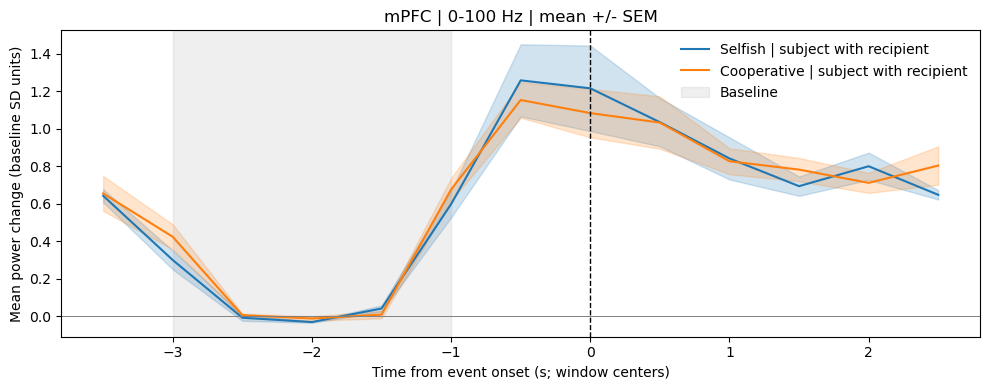

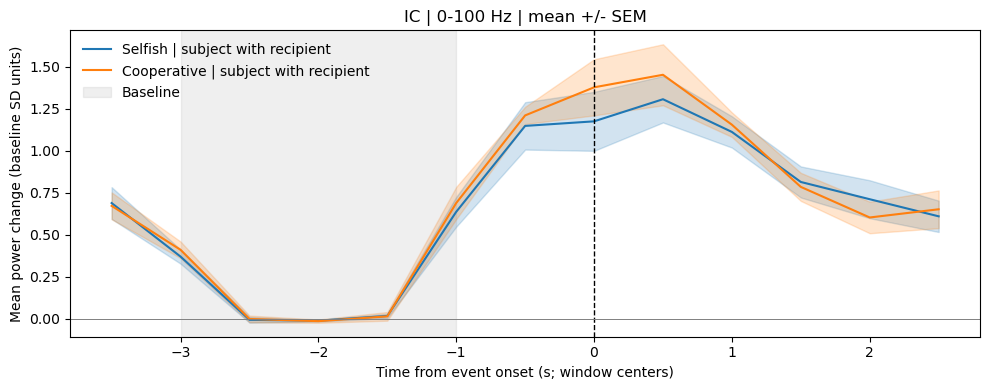

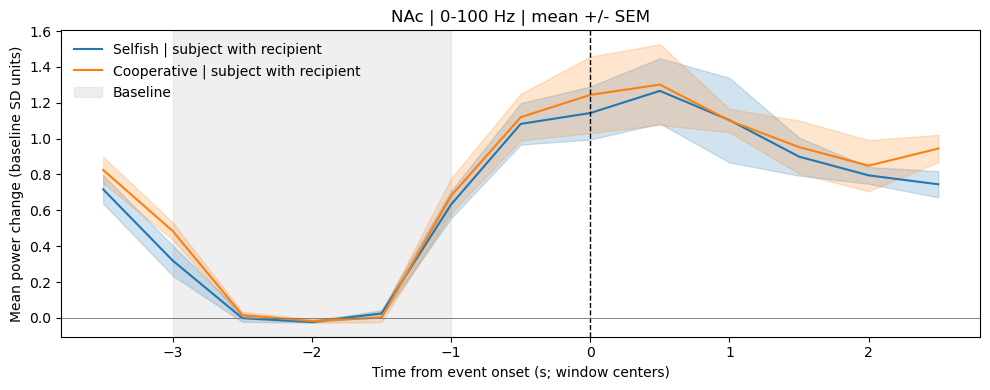

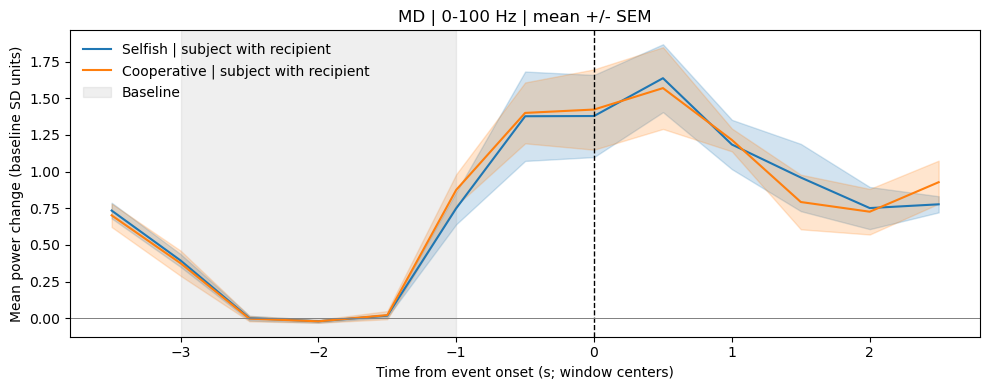

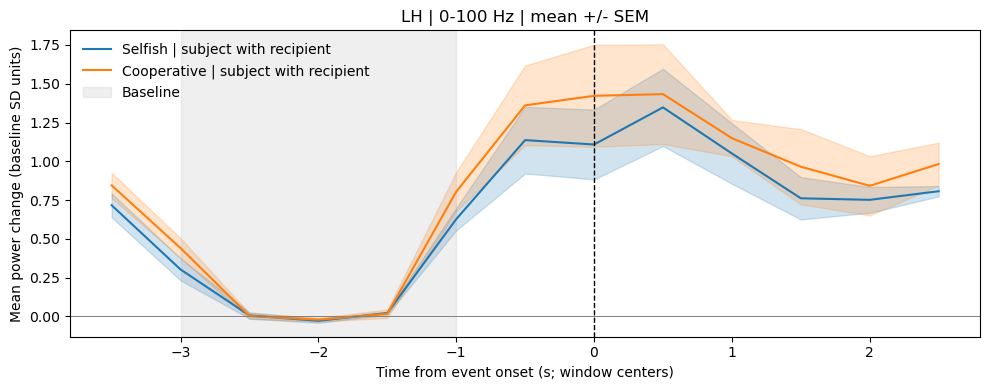

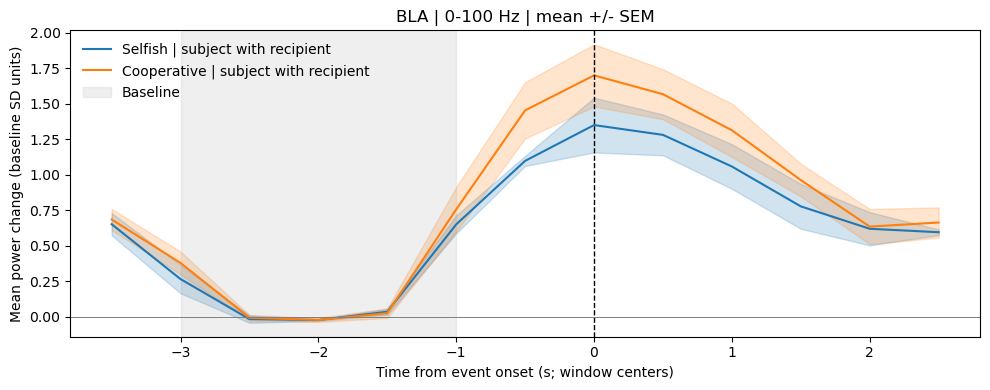

In [11]:
trace_results = {}
trace_results["power_choice"] = plot_baselined_event_average_traces(
    baseline_results["selfish_social"],
    comparison_result=baseline_results["coop_social"],
    labels=("Selfish | subject with recipient", "Cooperative | subject with recipient"),
)
plt.show()


## Export One Trialwise CSV per Recording and Figures

Each recording gets its own CSV, combining its selected events and conditions from
`baseline_results`. Files follow the reference layout: one row per selection, recording, event occurrence, time point, and region;
one column per frequency (`freq_001_4_Hz`, etc.). Cells contain per-event power
**z-scores**, not raw power or group averages. All selected points are retained,
including rows with missing values (empty CSV cells).

Metadata includes day, animal, role, recording, choice, event onset, and trial number.
`trial_number` is the original event index + 1 within each recording/event, not a
cross-animal matched trial number. `PAIRING_DICT` maps subjects to recipients;
`paired_subject_id` contains the other animal's ID on both animals' rows.
Both ID columns use hyphens (`1.2` becomes `1-2`) to match recording filenames. Alone
recordings have no partner. A missing social pairing raises an error before export.
`feature` identifies the brain region; `source_region`, `target_region`, and
`direction` are omitted because these exports contain power only. Alignment uses the
imported event's onset; no recipient light-delay alignment is introduced.
`alignment_source` is omitted because all events use this same alignment method.
`alignment_time_s` retains each event's onset time in the recording.

Additional columns identify the selection, condition, original event, stable trial ID,
normalization, baseline bounds, and time reference. Only the currently calculated
power frequencies/regions are exported; the example file's connectivity metrics and
1-100 Hz range are not introduced by changing the layout.

To reconstruct the figures, average each frequency across trials **within recording**.
For heatmaps, then average recordings equally. For lines, average those frequency
means within recording, then compute the group mean and SEM across recordings.
Averaging a trial's frequencies first can give different results when values are missing.
Baseline samples, statistics, QC, and summaries remain accessible in each result's
`tables` dictionary. Existing CSVs are protected unless `OVERWRITE_EXPORTS=True`.
Rerunning the settings cell makes a new run ID.


In [12]:
exported_files = {}
if EXPORT_CSV:
    exported_files = export_event_baseline_trialwise_csv(
        baseline_results, OUTPUT_DIR / "recordings",
        day=DAY, overwrite=OVERWRITE_EXPORTS, split_by_recording=True,
        pairing_dict=PAIRING_DICT,
    )
    display(pd.DataFrame([
        {"recording": recording, "csv": str(path), "size_mb": path.stat().st_size / 1_000_000}
        for recording, path in exported_files.items()
    ]))
    if exported_files:
        display(pd.read_csv(next(iter(exported_files.values())), nrows=5))

if SAVE_FIGURES:
    figure_dir = OUTPUT_DIR / "figures"
    figure_dir.mkdir(parents=True, exist_ok=True)
    for family, results in (("spectrogram", spectrogram_results), ("traces", trace_results)):
        for key, result in results.items():
            regions = result.get("regions", result.get("trace_labels", []))
            for region, ax in zip(regions, result["axes"]):
                safe_region = re.sub(r"[^A-Za-z0-9_-]+", "_", region)
                ax.figure.savefig(figure_dir / f"{family}_{key}_{safe_region}.png", dpi=180, bbox_inches="tight")
print("Outputs:", OUTPUT_DIR)


,recording,csv,size_mb
0,20250508_100203_Stage4_D1_1-2_merged.rec,C:\Users\zhaoz\Desktop\Research\Cooperation\co...,23.172773
1,20250508_100203_Stage4_D1_2-4_merged.rec,C:\Users\zhaoz\Desktop\Research\Cooperation\co...,19.509933
2,20250509_131426_Stage4_D1_4-3_merged.rec,C:\Users\zhaoz\Desktop\Research\Cooperation\co...,36.737438
3,20250509_131426_Stage4_D1_4-4_merged.rec,C:\Users\zhaoz\Desktop\Research\Cooperation\co...,32.994664


,day,animal_id,role,paired_subject_id,h5_file,rec_file,choice,trial_number,alignment_time_s,relative_time_s,...,freq_092_91_Hz,freq_093_92_Hz,freq_094_93_Hz,freq_095_94_Hz,freq_096_95_Hz,freq_097_96_Hz,freq_098_97_Hz,freq_099_98_Hz,freq_100_99_Hz,freq_101_100_Hz
0,1,1-2,subject,1-3,20250508_100203_Stage4_D1_1-2_merged.rec.h5,20250508_100203_Stage4_D1_1-2_merged.rec,coop,1,582.50055,-3.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,1-2,subject,1-3,20250508_100203_Stage4_D1_1-2_merged.rec.h5,20250508_100203_Stage4_D1_1-2_merged.rec,coop,1,582.50055,-3.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,1-2,subject,1-3,20250508_100203_Stage4_D1_1-2_merged.rec.h5,20250508_100203_Stage4_D1_1-2_merged.rec,coop,1,582.50055,-3.5,...,-1.844396,-2.148795,-0.830583,0.951075,2.627692,7.400372,3.931733,5.410785,11.375689,14.90079
3,1,1-2,subject,1-3,20250508_100203_Stage4_D1_1-2_merged.rec.h5,20250508_100203_Stage4_D1_1-2_merged.rec,coop,1,582.50055,-3.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,1-2,subject,1-3,20250508_100203_Stage4_D1_1-2_merged.rec.h5,20250508_100203_Stage4_D1_1-2_merged.rec,coop,1,582.50055,-3.5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Outputs: c:\Users\zhaoz\Desktop\Research\Cooperation\coop_ephys_analysis\results\lfp\event_baseline\D1\20261106T200503_275170Z


## Inspect or Reuse Individual Data Points

`trial_id` combines recording, event name, and original event index. It links trial power,
baseline samples/statistics, and QC. Original power means power from RMS-normalized
traces; it is not absolute voltage power. The prepared result can be reused for plotting
and export without recalculating spectra.

Alternatively call the new plot functions directly with `collection`, `event=...`,
`selected_condition=...`, and `**common`, just like the existing plotting functions.
For two lines, use `comparison_event` and/or `comparison_condition`. Direct calls
calculate their own results; the prepared-result route above avoids repeated work.


In [11]:
points = baseline_results["selfish_social"]["tables"]["trial_power"]
first_trial_id = points.trial_id.iloc[0]
display(points.loc[points.trial_id == first_trial_id].head(20))
display(baseline_results["selfish_social"]["tables"]["group_traces"].head(12))


,recording,subject,condition,event,trial_id,event_index,event_onset_s,relative_time_s,window_start_relative_s,window_stop_relative_s,frequency_hz,region,power,zscore,baseline_status
0,20250517_105306_Stage4_D8_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250517_105306_Stage4_D8_1-2_merged.rec"", ""...",0,1186.12895,-3.5,-3.99995,-2.99995,0.0,mPFC,0.003010,5.717278,ok
1,20250517_105306_Stage4_D8_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250517_105306_Stage4_D8_1-2_merged.rec"", ""...",0,1186.12895,-3.5,-3.99995,-2.99995,0.0,IC,0.004817,3.566530,ok
2,20250517_105306_Stage4_D8_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250517_105306_Stage4_D8_1-2_merged.rec"", ""...",0,1186.12895,-3.5,-3.99995,-2.99995,0.0,NAc,0.001908,9.111251,ok
3,20250517_105306_Stage4_D8_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250517_105306_Stage4_D8_1-2_merged.rec"", ""...",0,1186.12895,-3.5,-3.99995,-2.99995,0.0,MD,0.004925,20.340712,ok
4,20250517_105306_Stage4_D8_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250517_105306_Stage4_D8_1-2_merged.rec"", ""...",0,1186.12895,-3.5,-3.99995,-2.99995,0.0,LH,0.002244,-0.333598,ok
5,20250517_105306_Stage4_D8_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250517_105306_Stage4_D8_1-2_merged.rec"", ""...",0,1186.12895,-3.5,-3.99995,-2.99995,0.0,BLA,0.003062,1.211894,ok
6,20250517_105306_Stage4_D8_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250517_105306_Stage4_D8_1-2_merged.rec"", ""...",0,1186.12895,-3.5,-3.99995,-2.99995,1.0,mPFC,0.002098,-1.511689,ok
7,20250517_105306_Stage4_D8_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250517_105306_Stage4_D8_1-2_merged.rec"", ""...",0,1186.12895,-3.5,-3.99995,-2.99995,1.0,IC,0.004449,-0.537042,ok
8,20250517_105306_Stage4_D8_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250517_105306_Stage4_D8_1-2_merged.rec"", ""...",0,1186.12895,-3.5,-3.99995,-2.99995,1.0,NAc,0.001245,-2.179790,ok
9,20250517_105306_Stage4_D8_1-2_merged.rec,1.2,subject with recipient,filtered selfish nose poke,"[""20250517_105306_Stage4_D8_1-2_merged.rec"", ""...",0,1186.12895,-3.5,-3.99995,-2.99995,1.0,MD,0.002513,-3.035783,ok


,region,relative_time_s,mean_z,sd_z,n_recordings,sem_z
0,mPFC,-3.5,0.596155,0.460824,4,0.230412
1,IC,-3.5,-0.052870,1.364641,4,0.682320
2,NAc,-3.5,0.564401,0.457623,4,0.228811
3,MD,-3.5,0.698836,0.595514,4,0.297757
4,LH,-3.5,0.604618,0.502956,4,0.251478
5,BLA,-3.5,0.366172,0.640606,4,0.320303
6,mPFC,-3.0,0.401005,0.053198,4,0.026599
7,IC,-3.0,-0.076998,0.595561,4,0.297780
8,NAc,-3.0,0.235823,0.347695,4,0.173848
9,MD,-3.0,0.314645,0.310018,4,0.155009
